# Morning Colab run: background probe ("what is the model listening to?") + adversarial follow-up

Prerequisite: the Colab notebook session from yesterday (cells 1-3 run: settings with FREEZE_K = 0, GPU check,
Drive mounted). `RUNS`, `FB` and `REPORT` then point at the finished full-fine-tuning runs on Drive.


## Send back
- the printed table from step 2 (results and paired differences);
- `background_probe_db20/background_probe_results.csv`, `background_probe_paired_differences.csv`, `mask_summary.csv`;
- (if run) `{REPORT}_adv/paired_differences.csv` and `G9_source_clustering_of_embeddings.csv`.

## How to read step 2
- `full` vs `background`: how much performance is lost when the vocalisation is cut out.
- `background` vs `random` (same amount of audio removed elsewhere): proves the loss comes from removing the
  vocalisation specifically.
- `background` above `chance_95` (column `above_chance`): the model still recognises the class from what is
  left. If true on these unseen recordings, it's the striking result.
- `frozen-AST probe (train background)` tested on `background`: whether class information exists in the background
  at all, independent of the fine-tuned models.


In [5]:
%cd /content
import os, shutil, zipfile, glob
shutil.rmtree("/content/ns7k-src", ignore_errors=True)
!git clone -q -b analysis/source-identity https://github.com/Harbani007/nonspeech7k-generalisation.git /content/ns7k-src
%cd /content/ns7k-src
!pip -q install "transformers>=4.40" soundfile

os.makedirs("/content/splits", exist_ok=True)
shutil.copy("docs/results/splits/splits.csv", "/content/splits/splits.csv")

if not os.path.exists("/content/data/audio/.unpacked"):
    for z in ["train.zip", "test.zip"]:
        zipfile.ZipFile(f"{DRIVE_DIR}/{z}").extractall("/content/data/audio")
    open("/content/data/audio/.unpacked", "w").write("ok")

n_wav = sum(f.endswith(".wav") for _, _, fs in os.walk("/content/data/audio") for f in fs)
print("wav files:", n_wav, "(expect 7014)")
print("clips.csv:", os.path.exists(f"{FB}/clips.csv"))
print("finished runs:", len(glob.glob(f"{RUNS}/*/test_metrics.json")), "(expect 15)")
print("background_probe.py:", os.path.exists("background_probe.py"))
import torch; print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE: switch runtime to GPU")

/content
/content/ns7k-src
wav files: 7014 (expect 7014)
clips.csv: True
finished runs: 15 (expect 15)
background_probe.py: True
GPU: Tesla T4


In [2]:
## 1. Get the newest code (after `git push` from the laptop)

!rm -rf /content/ns7k-src && git clone -b analysis/source-identity https://github.com/Harbani007/nonspeech7k-generalisation.git /content/ns7k-src
%cd /content/ns7k-src
!pip -q install "transformers>=4.40" soundfile

Cloning into '/content/ns7k-src'...
remote: Enumerating objects: 259, done.
remote: Counting objects: 100% (259/259), done.
remote: Compressing objects: 100% (174/174), done.
remote: Total 259 (delta 93), reused 231 (delta 79), pack-reused 0 (from 0)
Receiving objects: 100% (259/259), 1.14 MiB | 22.89 MiB/s, done.
Resolving deltas: 100% (93/93), done.
/content/ns7k-src


preprocessor_config.json: 100% 297/297 [00:00<00:00, 1.42MB/s]
config.json: 100% 26.8k/26.8k [00:00<00:00, 53.4MB/s]

model.safetensors: downloading bytes:  90% 310M/346M [00:02<00:00, 256MB/s, 26.0MB/s  ]
model.safetensors: reconstructing file:  77% 268M/346M [00:02<00:00, 100MB/s]
model.safetensors: downloading bytes: 100% 334M/334M [00:03<00:00, 109MB/s, 30.4MB/s  ]
model.safetensors: reconstructing file: 100% 346M/346M [00:03<00:00, 113MB/s, 31.8MB/s  ]
Loading weights: 100% 199/199 [00:00<00:00, 5734.37it/s]
[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical ar

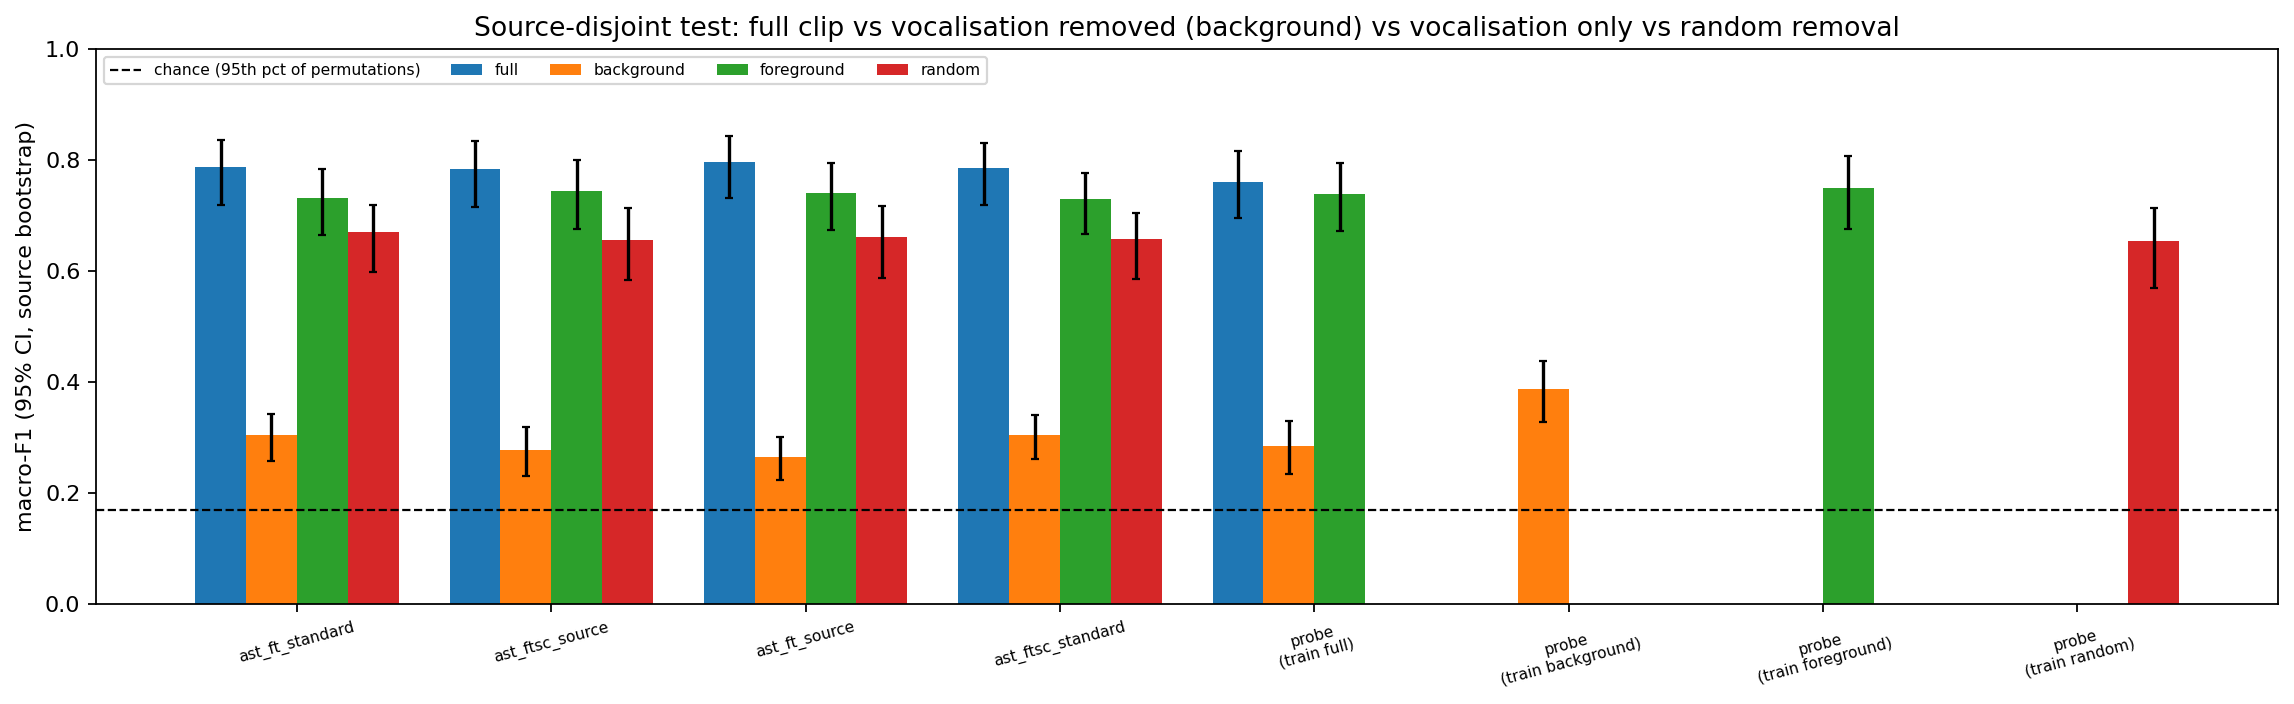

,system,a,b,macro_f1_a,macro_f1_b,b_minus_a,ci_lo,ci_hi,ci_excludes_zero
0,ast_ft_source_disjoint_source,full,background,0.797,0.265,-0.532,-0.583,-0.470,True
1,ast_ft_source_disjoint_source,background,random,0.265,0.662,0.397,0.328,0.452,True
2,ast_ft_source_disjoint_source,full,foreground,0.797,0.741,-0.056,-0.086,-0.029,True
3,ast_ft_source_disjoint_source,foreground,background,0.741,0.265,-0.476,-0.534,-0.409,True
4,ast_ft_source_disjoint_standard,full,background,0.788,0.304,-0.484,-0.539,-0.422,True
5,ast_ft_source_disjoint_standard,background,random,0.304,0.671,0.367,0.304,0.417,True
6,ast_ft_source_disjoint_standard,full,foreground,0.788,0.732,-0.056,-0.089,-0.026,True
7,ast_ft_source_disjoint_standard,foreground,background,0.732,0.304,-0.429,-0.488,-0.363,True
8,ast_ftsc_source_disjoint_source,full,background,0.784,0.277,-0.508,-0.563,-0.441,True
9,ast_ftsc_source_disjoint_source,background,random,0.277,0.655,0.379,0.312,0.436,True


breath__372241-4_0_0__background_only.wav


breath__372241-4_0_0__full.wav


breath__372241-7_0_0__background_only.wav


breath__372241-7_0_0__full.wav


cough__219-cough-aigei-1_1_0__background_only.wav


cough__219-cough-aigei-1_1_0__full.wav


In [6]:
## 2. Background probe (main new experiment, about 15-30 min on a T4)
# No training: it re-scores your trained checkpoints on modified test audio.

!python background_probe.py --data /content/splits --clips "{FB}/clips.csv" --audio-root /content/data/audio \
    --runs "{RUNS}" --out "{WORK}/background_probe_db20" --fg-db 20 --device cuda

# Sensitivity check, a less strict removal (optional, same time again):

!python background_probe.py --data /content/splits --clips "{FB}/clips.csv" --audio-root /content/data/audio \
    --runs "{RUNS}" --out "{WORK}/background_probe_db10" --fg-db 10 --device cuda

# Show the figure and listen to examples:

from IPython.display import Image, Audio, display
import pandas as pd, glob
display(Image(f"{WORK}/background_probe_db20/G10_background_probe.png"))
display(pd.read_csv(f"{WORK}/background_probe_db20/background_probe_paired_differences.csv").round(3))
for f in sorted(glob.glob(f"{WORK}/background_probe_db20/examples/*.wav"))[:6]:
    print(f.split("/")[-1]); display(Audio(f))

In [ ]:
## 3. Adversarial follow-up (optional, about 30-45 min)

!ADV=0.3 EPOCHS={EPOCHS} SPE={SPE} BATCH={BATCH} LR={LR} bash run_gpu_adv.sh python /content/splits "{FB}" "{RUNS}" {FREEZE_K} 0 1 2
!python dl_report.py --data /content/splits --runs "{RUNS}" --audit /content/splits --out "{REPORT}_adv" 2>&1 | grep -A12 "adversarial\|source clustering"

# If you run this BEFORE step 2, the background probe also scores the adversarial models.

/content/drive/MyDrive/ns7k/work/runs_k0_pc200/ast_ftadv_source_disjoint_standard_s0: TEST: acc 0.854 macroF1 0.839 bal_acc 0.860; max relative change of pretrained weights 0.3157
